# Time Series Demand Forecasting

### Key Business Outcomes:
- **Tuned XGBoost** achieved a **MAE of 21.62**, outperforming the Naive baseline (**MAE 43.45**) by **50.2%** and the 7-day average (**MAE 32.12**) by **32.7%**.
- **Primary Drivers:** SHAP analysis shows that **Price**, **Promotional Campaigns**, and **Groceries Category** have the highest overall impact on daily demand.

**What this notebook does**
1. Loads and checks the data
2. Time Series Feature Engineering
3. Exploratory Data Analysis on basis of demand
4. Trains and fine-tunes an **XGBoost** model using a **time-based** split
5. Checks performance with metrics and plots
6. Explains the model with **SHAP**

**Goal:** Predict daily `Demand` for each Store + Product.

## Step 1 · Setup And Configuration

Importing the libraries and setup clean plot style for the whole notebook.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from IPython.display import display

warnings.filterwarnings('ignore')

# ---- One look for all charts ----
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.titleweight': 'bold',
    'axes.titlesize': 14,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
MAIN = '#4C72B0'     # main colour
ACCENT = '#DD8452'   # highlight colour

## Step 2 · Loading the data and initial exploration

In [2]:
# Loading the data
df = pd.read_csv('/content/demand_forecasting.csv')
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [3]:
# Shape and info about the data
print('Shape:', df.shape)
df.info()

Shape: (76000, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  object 
 1   Store ID            76000 non-null  object 
 2   Product ID          76000 non-null  object 
 3   Category            76000 non-null  object 
 4   Region              76000 non-null  object 
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  object 
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  object 
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null

In [4]:
# .Cheacking for missing and duplicate values
print('Missing values per column:')
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().any().any() else 'None')
print('\nDuplicate rows:', df.duplicated().sum())

Missing values per column:
None

Duplicate rows: 0


In [5]:
# describe gives the statical analysis of data
display(df.describe(include='number').T.round(2))
display(df.describe(include='object').T)

,count,mean,std,min,25%,50%,75%,max
Inventory Level,76000.0,301.06,226.51,0.00,136.00,227.0,408.00,2267.00
Units Sold,76000.0,88.83,43.99,0.00,58.00,84.0,114.00,426.00
Units Ordered,76000.0,89.09,162.40,0.00,0.00,0.0,121.00,1616.00
Price,76000.0,67.73,39.38,4.74,32.00,64.5,95.83,228.03
Discount,76000.0,9.09,7.48,0.00,5.00,10.0,10.00,25.00
Promotion,76000.0,0.33,0.47,0.00,0.00,0.0,1.00,1.00
Competitor Pricing,76000.0,69.45,40.94,4.29,32.62,65.7,97.93,261.22
Epidemic,76000.0,0.20,0.40,0.00,0.00,0.0,0.00,1.00
Demand,76000.0,104.32,46.96,4.00,71.00,100.0,133.00,430.00


,count,unique,top,freq
Date,76000,760,2024-01-30,100
Store ID,76000,5,S001,15200
Product ID,76000,20,P0001,3800
Category,76000,5,Groceries,30400
Region,76000,4,North,30400
Weather Condition,76000,4,Cloudy,24360
Seasonality,76000,4,Winter,21000


## Step 3 · Time Series Feature Engineering

**What we do in this step:**
- Convert `Date` to a real date and sort the data by time.
- Add calendar columns (month, weekday, quarter, weekend).
- Add `Discounted Price`, `Price Gap` (our price minus competitor price) and `Sell Through Rate`.

**Why:** Demand often changes by month and weekday, and by how our price compares with others. Sorting by date is a must for time-series work.

In [6]:
# Converting date to datetime
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['Date', 'Store ID', 'Product ID']).reset_index(drop=True)

# Calendar features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['WeekDay'] = df['Date'].dt.day_name()
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)
df['Quarter'] = df['Date'].dt.quarter
df['IsWeekend'] = (df['DayOfWeek'] >= 5).astype(int)

# Price features
df['Discounted Price'] = df['Price'] * (1 - df['Discount'] / 100)
df['Price Gap'] = df['Price'] - df['Competitor Pricing']

# Sell-through
df['Sell Through Rate'] = df['Units Sold'] / df['Inventory Level'].replace(0, np.nan)

print('Date range :', df['Date'].min().date(), '→', df['Date'].max().date())
print('Rows per day (min / max):', df.groupby('Date').size().min(), '/', df.groupby('Date').size().max())
print('Stores:', df['Store ID'].nunique(), '| Products:', df['Product ID'].nunique())
print('\n OUTCOME: Created 11 calendar and pricing features for 5 stores and 20 products spanning 2022 to 2024.')
df.head()

Date range : 2022-01-01 → 2024-01-30
Rows per day (min / max): 100 / 100
Stores: 5 | Products: 20


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,...,Month,Day,WeekDay,DayOfWeek,WeekOfYear,Quarter,IsWeekend,Discounted Price,Price Gap,Sell Through Rate
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,...,1,1,Saturday,5,52,1,1,69.084,-13.01,0.523077
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,...,1,1,Saturday,5,52,1,1,68.136,-11.86,1.000000
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,...,1,1,Saturday,5,52,1,1,56.646,2.86,0.461538
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,...,1,1,Saturday,5,52,1,1,78.867,2.44,0.323741
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,...,1,1,Saturday,5,52,1,1,54.410,2.78,0.427632


## Step 4 · Quick numbers before the charts

**What:** Simple group summaries of demand.

**Why:** Tables give exact values. The charts in the next step make the same patterns easy to see.

In [7]:
display(df.groupby('Category')['Demand'].agg(['mean', 'sum', 'min', 'max']).sort_values('mean', ascending=False).round(1))
display(df.groupby('Promotion')['Demand'].agg(['mean', 'count']).round(1))

,mean,sum,min,max
Category,,,,
Groceries,121.0,3677684,4,430
Clothing,112.6,1369456,4,330
Electronics,97.5,889036,4,339
Toys,92.6,985338,4,361
Furniture,73.6,1006590,4,214


,mean,count
Promotion,,
0,95.0,51000
1,123.3,25000


## Step 5 · Exploratory Data Analysis

We look at the data from a few angles: **how demand is spread, how it moves over time, what drives it, and how features relate.**

### 5.1 How is demand spread?

**What:** A histogram (with a smooth curve) and a boxplot of `Demand`.

**Why:** It shows the typical demand, how wide it varies and whether there are extreme values. If the data is skewed, we know the model will find big values harder to predict.

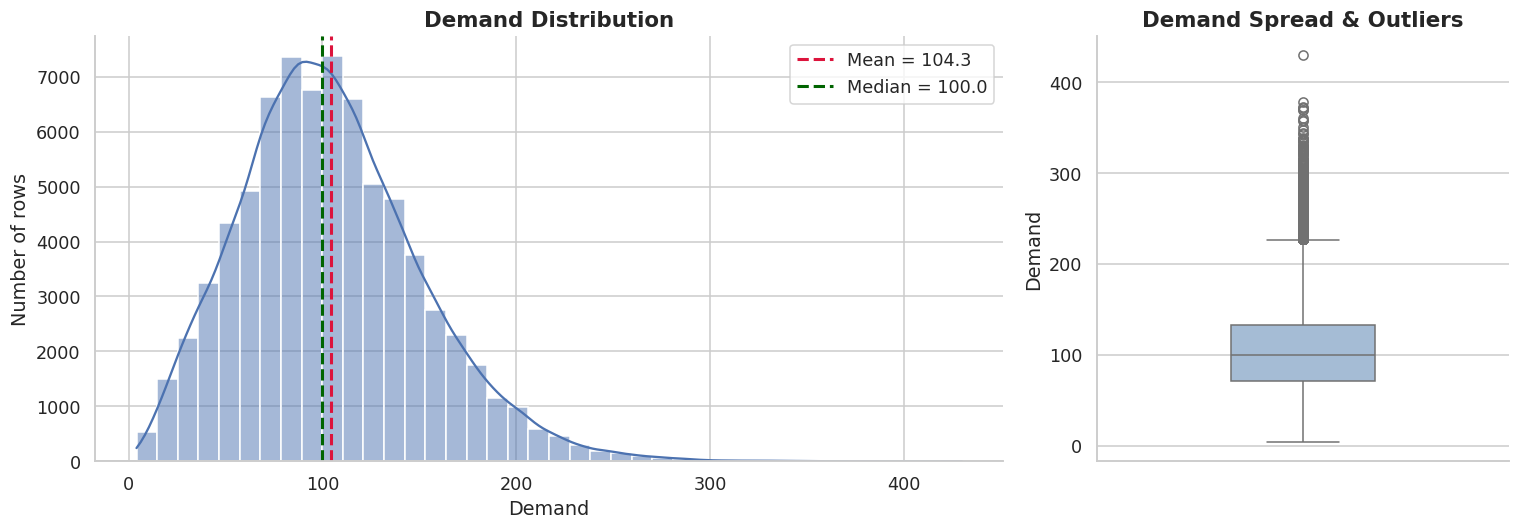

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [2.2, 1]})

sns.histplot(df['Demand'], bins=40, kde=True, color=MAIN, edgecolor='white', ax=axes[0])
axes[0].axvline(df['Demand'].mean(), color='crimson', ls='--', lw=2, label=f"Mean = {df['Demand'].mean():.1f}")
axes[0].axvline(df['Demand'].median(), color='darkgreen', ls='--', lw=2, label=f"Median = {df['Demand'].median():.1f}")
axes[0].set(title='Demand Distribution', xlabel='Demand', ylabel='Number of rows')
axes[0].legend()

sns.boxplot(y=df['Demand'], color='#9DBBDD', width=0.35, ax=axes[1])
axes[1].set(title='Demand Spread & Outliers', ylabel='Demand')

plt.tight_layout()
plt.show()

### 5.2 Demand over time

**What:** Total daily demand with a 30-day moving average on top.

**Why:** The thick line hides day-to-day noise so we can spot **trend** and **seasonal waves**. This tells us we need time-based features.

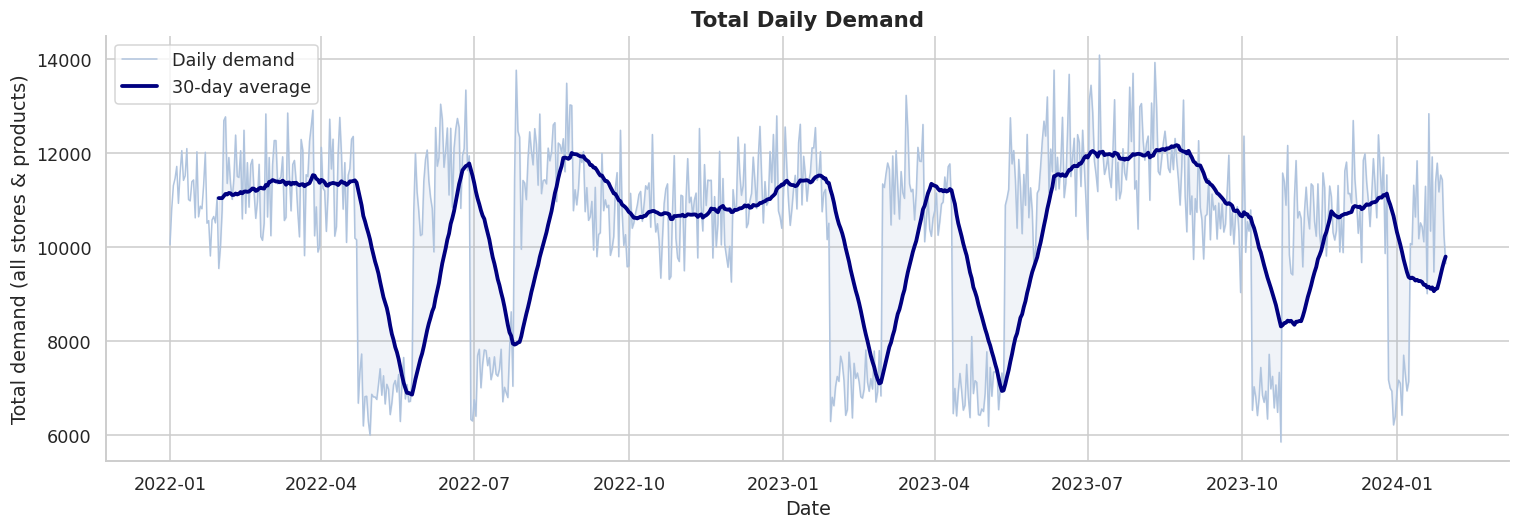

In [9]:
daily = df.groupby('Date')['Demand'].sum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily.index, daily.values, color='lightsteelblue', lw=1, label='Daily demand')
ax.plot(daily.index, daily.rolling(30).mean(), color='navy', lw=2.5, label='30-day average')
ax.fill_between(daily.index, daily.values, daily.rolling(30).mean(), color=MAIN, alpha=0.08)
ax.set(title='Total Daily Demand', xlabel='Date', ylabel='Total demand (all stores & products)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### 5.3 Seasonality: month and weekday

**What:** Average demand per month (one line per year) and per weekday.

**Why:** If the lines repeat each year, demand is seasonal. If some weekdays are higher, the model should know the weekday.

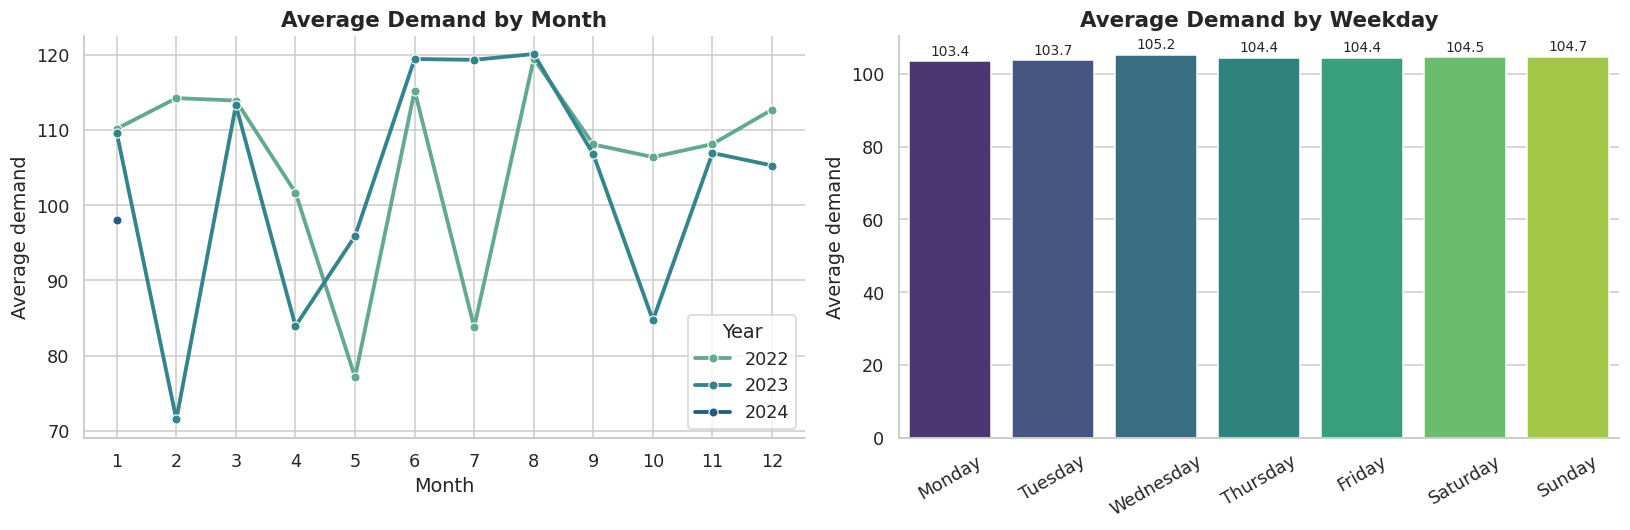

In [10]:
month_year = df.groupby(['Year', 'Month'])['Demand'].mean().reset_index()
month_year['Year'] = month_year['Year'].astype(str)
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
wd = df.groupby('WeekDay')['Demand'].mean().reindex(order).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(data=month_year, x='Month', y='Demand', hue='Year', palette='crest',
             marker='o', lw=2.5, ax=axes[0])
axes[0].set(title='Average Demand by Month', xlabel='Month', ylabel='Average demand')
axes[0].set_xticks(range(1, 13))

sns.barplot(data=wd, x='WeekDay', y='Demand', hue='WeekDay', palette='viridis', legend=False, ax=axes[1])
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.1f', padding=2, fontsize=9)
axes[1].set(title='Average Demand by Weekday', xlabel='', ylabel='Average demand')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### 5.4 Which categories sell the most?

**What:** Average demand per category (bars) and the full spread (boxplot).

**Why:** Categories behave differently. The bar shows who is bigger; the box shows who is more unpredictable.

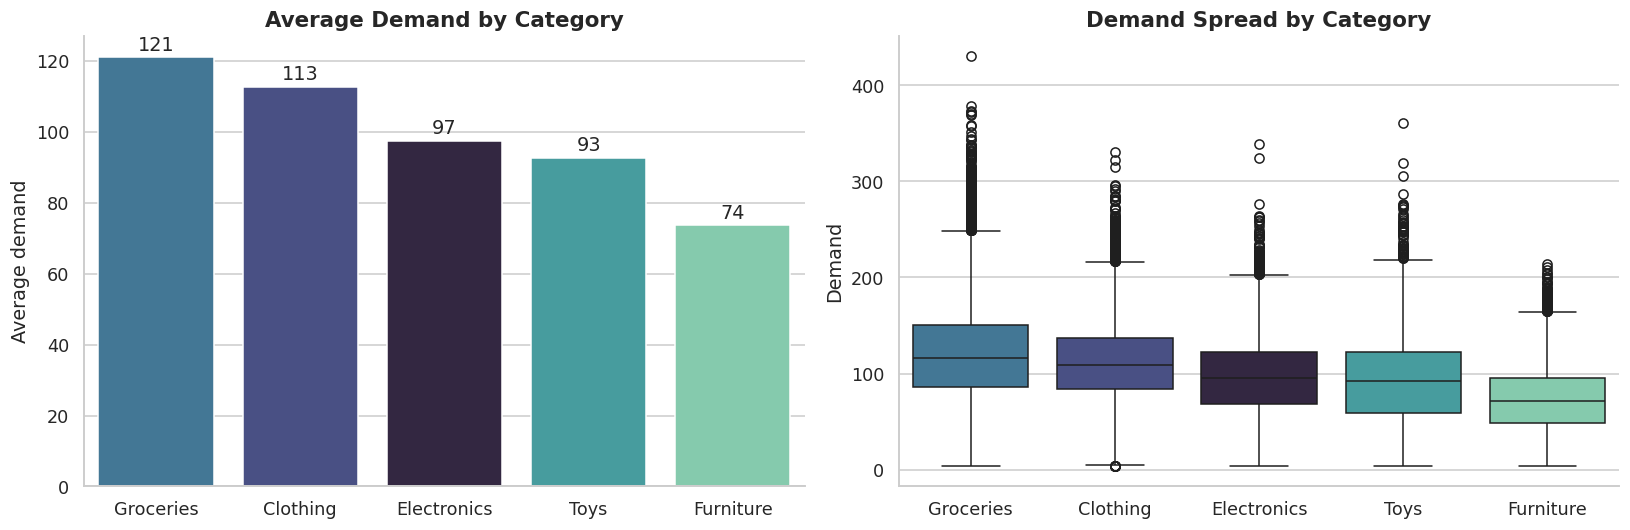

In [11]:
cat_order = df.groupby('Category')['Demand'].mean().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=df, x='Category', y='Demand', order=cat_order, hue='Category', palette='mako',
            errorbar=None, legend=False, ax=axes[0])
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.0f', padding=2)
axes[0].set(title='Average Demand by Category', xlabel='', ylabel='Average demand')

sns.boxplot(data=df, x='Category', y='Demand', order=cat_order, hue='Category', palette='mako',
            legend=False, ax=axes[1])
axes[1].set(title='Demand Spread by Category', xlabel='', ylabel='Demand')

plt.tight_layout()
plt.show()

### 5.5 Heatmaps: where and when is demand high?

**What:** Two colour grids: **Region × Season** and **Month × Category**.

**Why:** A heatmap shows combinations at a glance. Darker colour = higher average demand.

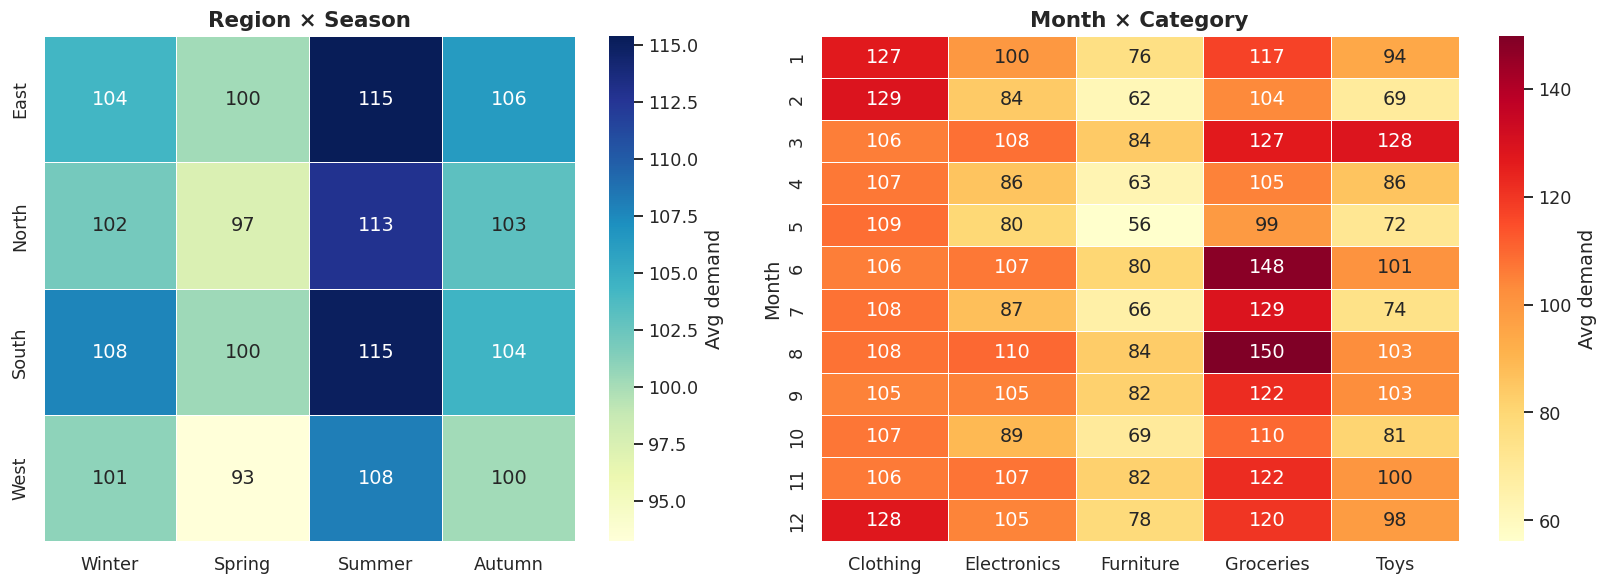

In [12]:
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
reg_season = df.pivot_table(values='Demand', index='Region', columns='Seasonality', aggfunc='mean')[season_order]
month_cat = df.pivot_table(values='Demand', index='Month', columns='Category', aggfunc='mean')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.2]})

sns.heatmap(reg_season, annot=True, fmt='.0f', cmap='YlGnBu', linewidths=.5, cbar_kws={'label': 'Avg demand'}, ax=axes[0])
axes[0].set(title='Region × Season', xlabel='', ylabel='')

sns.heatmap(month_cat, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=.5, cbar_kws={'label': 'Avg demand'}, ax=axes[1])
axes[1].set(title='Month × Category', xlabel='', ylabel='Month')

plt.tight_layout()
plt.show()

### 5.6 Price, discount and demand

**What:** Scatter plots of price vs demand (coloured by category) and the average demand at each discount level.

**Why:** We want to see if cheaper items sell more and if bigger discounts really lift demand. (A random sample is plotted to keep the chart clear and fast.)

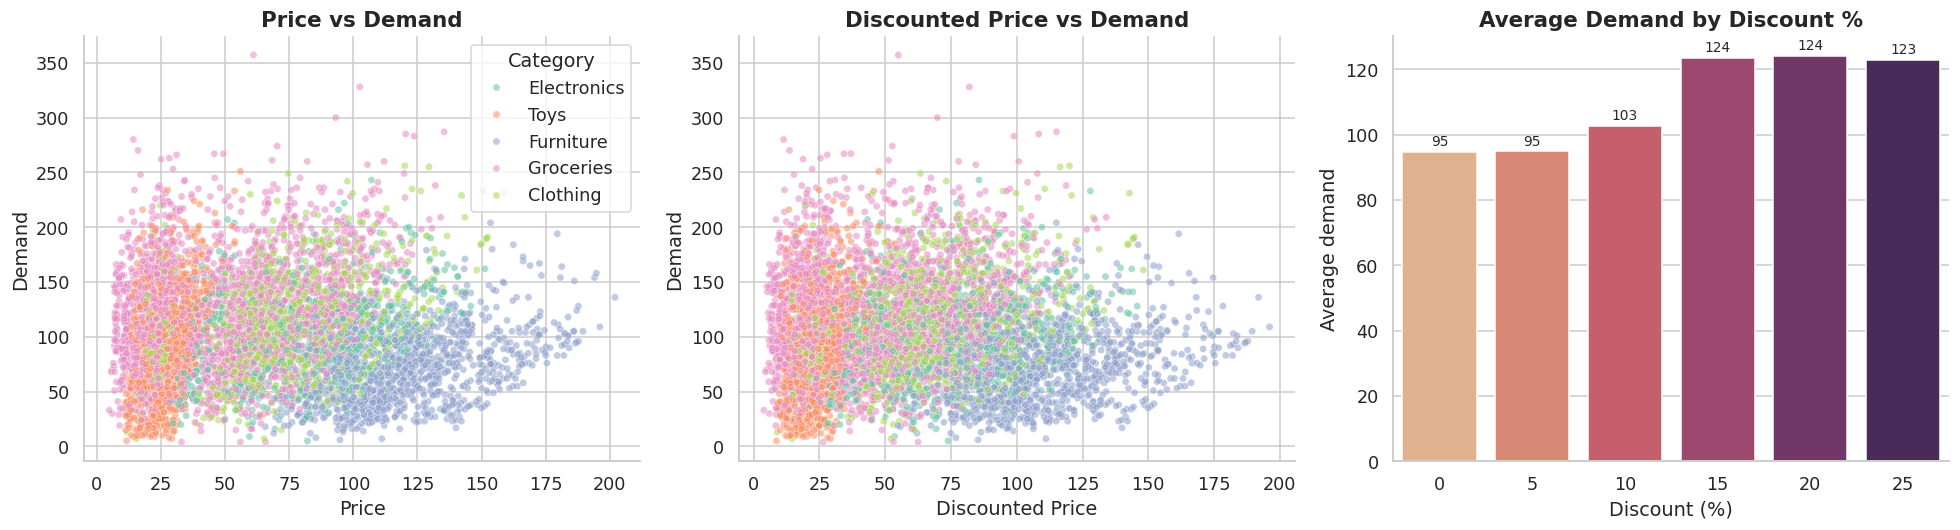

In [13]:
sample = df.sample(6000, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=sample, x='Price', y='Demand', hue='Category', palette='Set2', alpha=0.55, s=22, ax=axes[0])
axes[0].set(title='Price vs Demand')

sns.scatterplot(data=sample, x='Discounted Price', y='Demand', hue='Category', palette='Set2', alpha=0.55, s=22,
                legend=False, ax=axes[1])
axes[1].set(title='Discounted Price vs Demand')

disc = df.groupby('Discount')['Demand'].mean().reset_index()
sns.barplot(data=disc, x='Discount', y='Demand', hue='Discount', palette='flare', legend=False, ax=axes[2])
for c in axes[2].containers:
    axes[2].bar_label(c, fmt='%.0f', padding=2, fontsize=9)
axes[2].set(title='Average Demand by Discount %', xlabel='Discount (%)', ylabel='Average demand')

plt.tight_layout()
plt.show()

### 5.7 External drivers: promotion, epidemic, weather, store

**What:** Average demand for each value of four business factors.

**Why:** These are things the business can plan for or react to. Big gaps between bars mean the factor matters for the forecast.

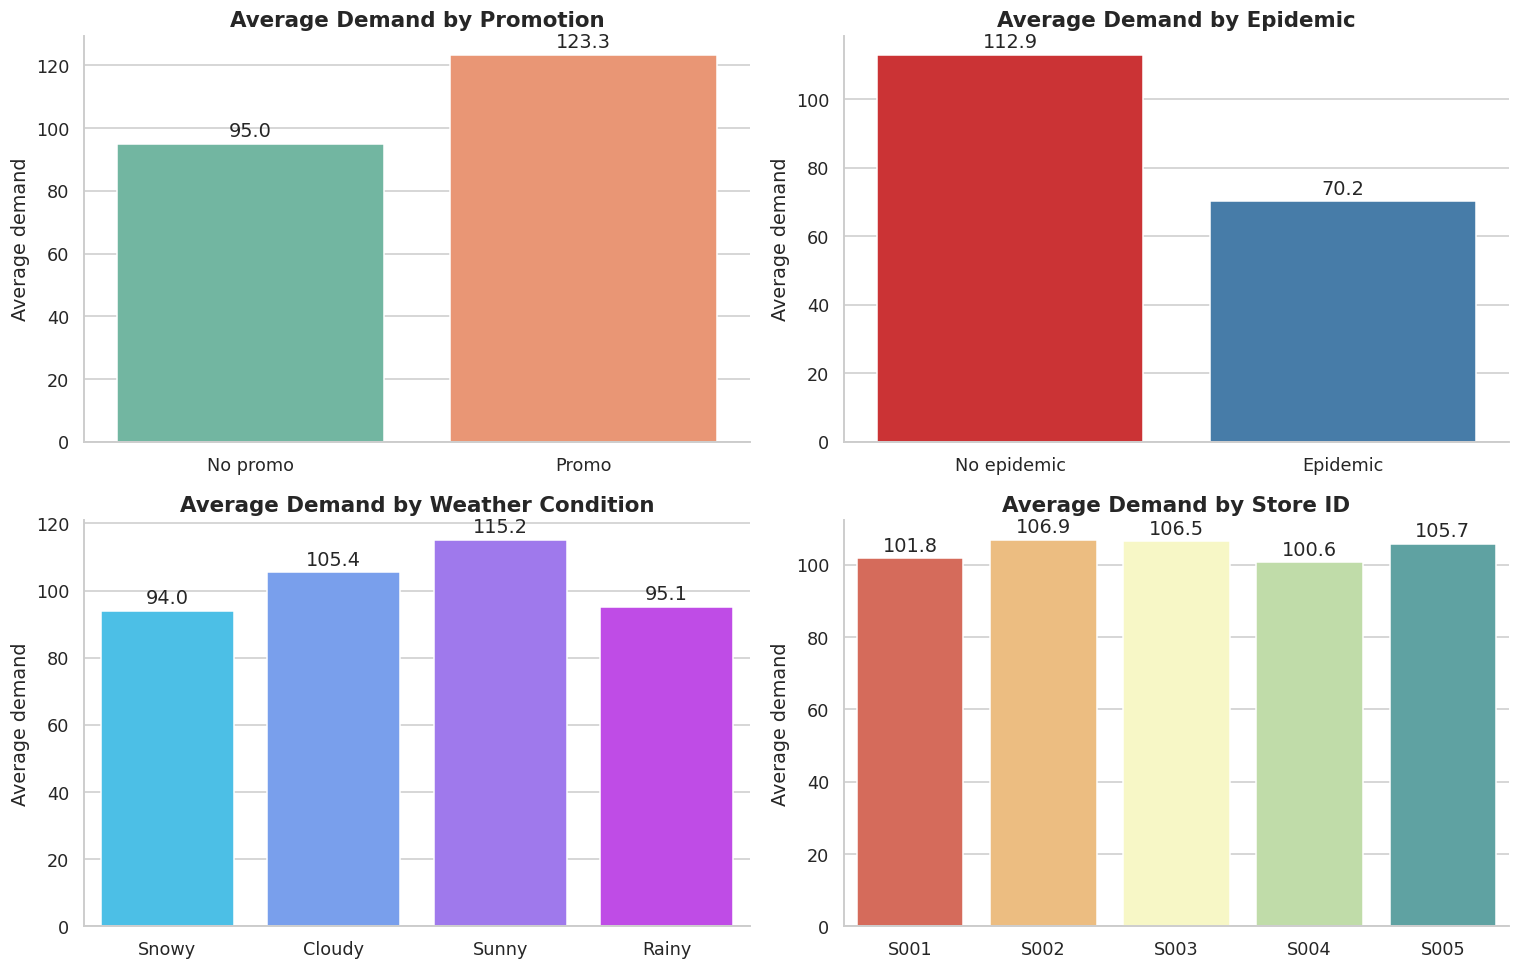

In [14]:
plot_df = df.copy()
plot_df['Promotion'] = plot_df['Promotion'].map({0: 'No promo', 1: 'Promo'})
plot_df['Epidemic'] = plot_df['Epidemic'].map({0: 'No epidemic', 1: 'Epidemic'})

drivers = ['Promotion', 'Epidemic', 'Weather Condition', 'Store ID']
palettes = ['Set2', 'Set1', 'cool', 'Spectral']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col, pal in zip(axes.ravel(), drivers, palettes):
    sns.barplot(data=plot_df, x=col, y='Demand', hue=col, palette=pal, errorbar=None, legend=False, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt='%.1f', padding=2)
    ax.set(title=f'Average Demand by {col}', xlabel='', ylabel='Average demand')

plt.tight_layout()
plt.show()

### 5.8 Correlation heatmap

**What:** How strongly each number column moves together with the others (−1 to +1).

**Why:** It shows which numbers relate to `Demand`. `Units Sold` and `Inventory Level` look closely tied to demand, but they are only known **after** the day happens. We will **not** use them as inputs for forecasting (see Step 6).

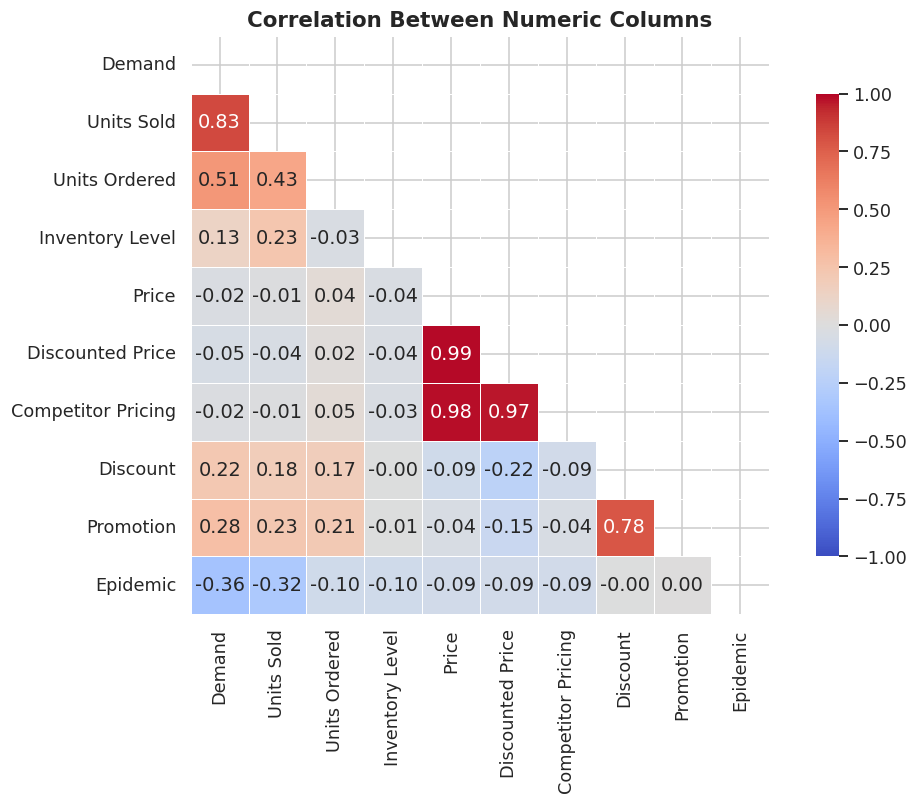

In [15]:
num_cols = ['Demand', 'Units Sold', 'Units Ordered', 'Inventory Level', 'Price', 'Discounted Price',
            'Competitor Pricing', 'Discount', 'Promotion', 'Epidemic']
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 7.5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=.5, square=True, cbar_kws={'shrink': .8})
plt.title('Correlation Between Numeric Columns')
plt.tight_layout()
plt.show()

### 5.9 Does yesterday predict today? (autocorrelation)

**What:** Correlation of total daily demand with its own past values (lag 1 to 40 days).

**Why:** Tall bars mean past demand carries information about future demand. That supports using **lag features** in the model.

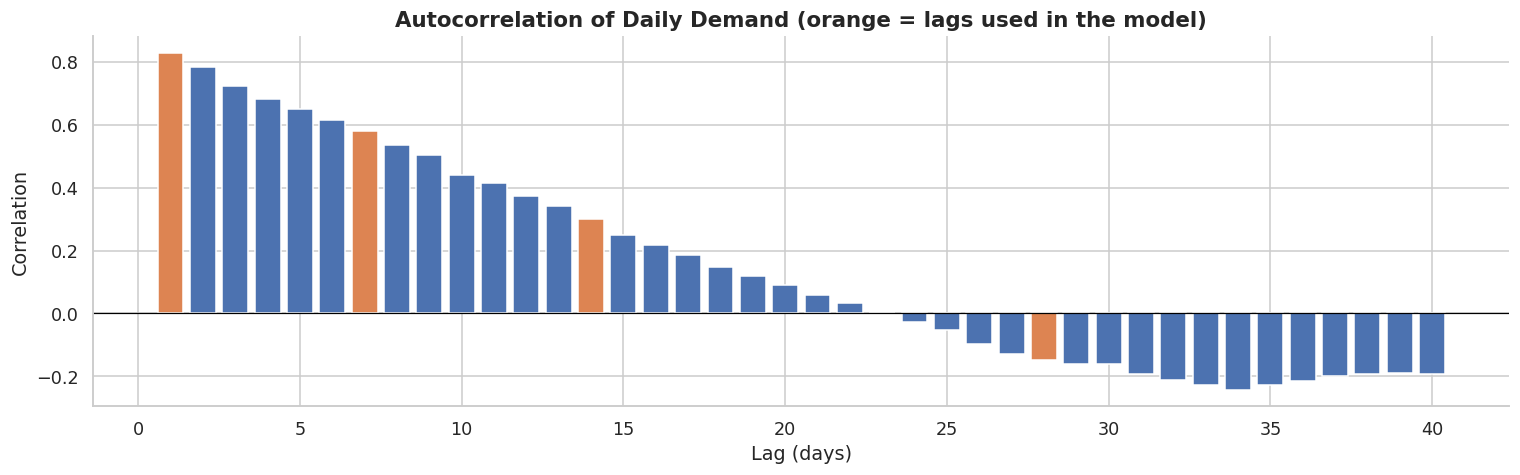

In [16]:
lags = range(1, 41)
acf = pd.Series([daily.autocorr(l) for l in lags], index=lags)

fig, ax = plt.subplots(figsize=(14, 4.5))
colors = [ACCENT if l in (1, 7, 14, 28) else MAIN for l in acf.index]
ax.bar(acf.index, acf.values, color=colors)
ax.axhline(0, color='black', lw=0.8)
ax.set(title='Autocorrelation of Daily Demand (orange = lags used in the model)',
       xlabel='Lag (days)', ylabel='Correlation')
plt.tight_layout()
plt.show()

## Step 6 · Build forecasting features

**What:** Create inputs the model can use to predict demand:
- **Lag features:** demand 1, 7, 14 and 28 days ago for the same Store + Product.
- **Rolling features:** average demand (and variation) over the last 7 and 28 days.
- **Planned features:** price, discount, promotion, competitor price, calendar, weather, season, epidemic flag.

**Why:** In real life we forecast *tomorrow* using what we know *today*. So we use past demand (lags) and things we can plan or know in advance.

**Important choice:** We **leave out** `Units Sold`, `Units Ordered` and `Inventory Level` from the same day. They are results of that day's demand, so using them would be *cheating* (data leakage). The model would look great in the notebook but fail in real use.

All lag/rolling values use `shift(1)` first, so a row never sees its own demand.

In [17]:
df_fe = df.sort_values(['Store ID', 'Product ID', 'Date']).copy()
grp = df_fe.groupby(['Store ID', 'Product ID'])['Demand']

# Lag features (same Store + Product)
for lag in [1, 7, 14, 28]:
    df_fe[f'lag_{lag}'] = grp.shift(lag)

# Rolling features (shift(1) so today's demand is never included)
df_fe['roll_mean_7'] = grp.transform(lambda s: s.shift(1).rolling(7).mean())
df_fe['roll_mean_28'] = grp.transform(lambda s: s.shift(1).rolling(28).mean())
df_fe['roll_std_7'] = grp.transform(lambda s: s.shift(1).rolling(7).std())

num_feats = ['Price', 'Discount', 'Discounted Price', 'Competitor Pricing', 'Price Gap',
             'Promotion', 'Epidemic',
             'Month', 'Day', 'DayOfWeek', 'WeekOfYear', 'Quarter', 'IsWeekend',
             'lag_1', 'lag_7', 'lag_14', 'lag_28', 'roll_mean_7', 'roll_mean_28', 'roll_std_7']
cat_feats = ['Category', 'Region', 'Weather Condition', 'Seasonality']

# The first 28 days of each series have no full history, so drop them
before = len(df_fe)
df_fe = df_fe.dropna(subset=num_feats).sort_values('Date').reset_index(drop=True)
print(f'Dropped {before - len(df_fe):,} early rows without enough history | Remaining: {len(df_fe):,}')

# One-hot encode the text columns (XGBoost needs numbers)
X = pd.get_dummies(df_fe[num_feats + cat_feats], columns=cat_feats, dtype=int)
y = df_fe['Demand']
print('Number of model features:', X.shape[1])
X.head()

Dropped 2,800 early rows without enough history | Remaining: 73,200
Number of model features: 37


,Price,Discount,Discounted Price,Competitor Pricing,Price Gap,Promotion,Epidemic,Month,Day,DayOfWeek,...,Region_South,Region_West,Weather Condition_Cloudy,Weather Condition_Rainy,Weather Condition_Snowy,Weather Condition_Sunny,Seasonality_Autumn,Seasonality_Spring,Seasonality_Summer,Seasonality_Winter
0,65.00,5,61.7500,77.11,-12.11,0,0,1,29,5,...,0,0,0,0,0,1,0,0,0,1
1,34.04,10,30.6360,30.25,3.79,0,0,1,29,5,...,0,1,0,0,0,1,0,0,0,1
2,74.96,5,71.2120,85.00,-10.04,0,0,1,29,5,...,0,1,0,0,0,1,0,0,0,1
3,69.45,5,65.9775,67.58,1.87,0,0,1,29,5,...,0,1,0,0,0,1,0,0,0,1
4,86.10,0,86.1000,91.39,-5.29,0,0,1,29,5,...,0,0,0,0,0,1,0,0,0,1


## Step 7 · Split the data by time

**What:**
- **Test:** the last 90 days (the "future" we try to predict).
- **Validation:** the 60 days before the test (used to stop training at the right time).
- **Train:** everything earlier.

**Why:** A random split mixes future rows into training, which makes the score look better than it really is. In forecasting we must **train on the past and test on the future**.

Train (fit) : 2022-01-29 → 2023-09-02  (58,200 rows)
Validation  : 2023-09-03 → 2023-11-01  (6,000 rows)
Test        : 2023-11-02 → 2024-01-30  (9,000 rows)


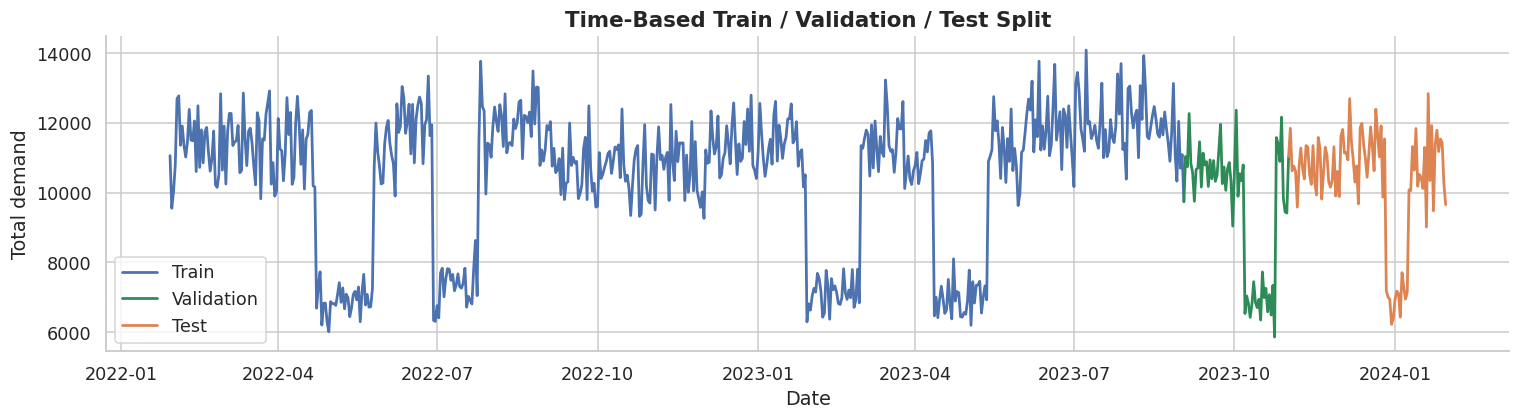

In [18]:
TEST_DAYS, VAL_DAYS = 90, 60

cut_test = df_fe['Date'].max() - pd.Timedelta(days=TEST_DAYS)
cut_val = cut_test - pd.Timedelta(days=VAL_DAYS)

train_mask = df_fe['Date'] <= cut_test            # train + validation
fit_mask = df_fe['Date'] <= cut_val               # pure training part
val_mask = train_mask & ~fit_mask                 # validation part
test_mask = ~train_mask

X_train, y_train = X[train_mask], y[train_mask]
X_fit, y_fit = X[fit_mask], y[fit_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

for name, m in [('Train (fit)', fit_mask), ('Validation', val_mask), ('Test', test_mask)]:
    d = df_fe.loc[m, 'Date']
    print(f'{name:<12}: {d.min().date()} → {d.max().date()}  ({m.sum():,} rows)')

# Visual check of the split
daily_total = df_fe.groupby('Date')['Demand'].sum()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily_total.index, daily_total.values, color='lightgray', lw=1)
for (start, end, col, lab) in [(df_fe['Date'].min(), cut_val, MAIN, 'Train'),
                               (cut_val, cut_test, 'seagreen', 'Validation'),
                               (cut_test, df_fe['Date'].max(), ACCENT, 'Test')]:
    seg = daily_total[(daily_total.index >= start) & (daily_total.index <= end)]
    ax.plot(seg.index, seg.values, color=col, lw=1.8, label=lab)
ax.set(title='Time-Based Train / Validation / Test Split', xlabel='Date', ylabel='Total demand')
ax.legend()
plt.tight_layout()
plt.show()

## Step 8 · Baselines and a first XGBoost model

**What:**
1. **Naive baseline:** "demand will be the same as 7 days ago".
2. **Average baseline:** "demand will be the last 7-day average".
3. **XGBoost with default-ish settings.**

**Why:**
- A fancy model is only useful if it beats simple rules, so baselines give us a bar to clear.
- **XGBoost** is chosen because it handles mixed features well, finds non-linear patterns (e.g. promo × season) without scaling, is fast, and usually wins on table-shaped data like this. Once we have lag features, it works nicely as a time-series forecaster.

**Metrics used** (all in plain words):
- **MAE:** average miss in units. Easiest to understand.
- **RMSE:** like MAE but punishes big misses more.
- **MAPE:** average miss in %.
- **R²:** how much of the ups and downs the model explains (1 is perfect).

In [19]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

def evaluate(y_true, y_pred, name):
    return {'Model': name,
            'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAPE %': mean_absolute_percentage_error(y_true, y_pred) * 100,
            'R2': r2_score(y_true, y_pred)}

# Settings shared by every XGBoost model below
BASE = dict(objective='reg:squarederror', tree_method='hist', random_state=42, n_jobs=-1)

# 1) Baselines (no training needed)
pred_naive = X_test['lag_7']
pred_avg7 = X_test['roll_mean_7']

# 2) First XGBoost model
xgb_default = XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, **BASE)
xgb_default.fit(X_train, y_train)
pred_default = xgb_default.predict(X_test)

results = pd.DataFrame([
    evaluate(y_test, pred_naive, 'Naive (same as 7 days ago)'),
    evaluate(y_test, pred_avg7, '7-day average'),
    evaluate(y_test, pred_default, 'XGBoost (default)'),
])
display(results.round(3))

,Model,MAE,RMSE,MAPE %,R2
0,Naive (same as 7 days ago),43.447,55.384,59.537,-0.563
1,7-day average,32.124,41.215,45.899,0.134
2,XGBoost (default),22.485,29.850,32.209,0.546


## Step 9 · Fine-tune XGBoost (hyper-parameter search)

**What:** Try 20 random combinations of key XGBoost settings and keep the best one.

| Setting | Plain meaning |
|---|---|
| `learning_rate` | how big each learning step is (small = careful) |
| `max_depth` | how complex each tree can be |
| `min_child_weight`, `gamma` | stop the model from learning tiny, noisy patterns |
| `subsample`, `colsample_bytree` | each tree sees only part of the rows/columns, which reduces overfitting |
| `reg_alpha`, `reg_lambda` | penalty that keeps the model simple |

**Why this method:**
- **RandomizedSearchCV** is much faster than trying every combination, and usually finds a very good one.
- **TimeSeriesSplit** makes every validation fold come *after* its training data, so tuning respects time order. (Normal K-fold would leak the future.)
- We score with **MAE** because it is easy to explain in business terms.

In [20]:
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

param_dist = {
    'n_estimators':     randint(200, 800),
    'learning_rate':    uniform(0.01, 0.14),
    'max_depth':        randint(3, 9),
    'min_child_weight': randint(1, 10),
    'subsample':        uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'gamma':            uniform(0, 0.5),
    'reg_alpha':        uniform(0, 1),
    'reg_lambda':       uniform(0.5, 2),
}

search = RandomizedSearchCV(
    estimator=XGBRegressor(**BASE),
    param_distributions=param_dist,
    n_iter=20,
    scoring='neg_mean_absolute_error',
    cv=TimeSeriesSplit(n_splits=3),
    random_state=42,
    n_jobs=1,
    verbose=1,
)
search.fit(X_train, y_train)

print(f'\nBest CV MAE: {-search.best_score_:.3f}')
print('Best settings:')
for k, v in search.best_params_.items():
    print(f'  {k:<17}: {v:.4f}' if isinstance(v, float) else f'  {k:<17}: {v}')

Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best CV MAE: 23.082
Best settings:
  colsample_bytree : 0.6488
  gamma            : 0.2476
  learning_rate    : 0.0148
  max_depth        : 8
  min_child_weight : 1
  n_estimators     : 761
  reg_alpha        : 0.6625
  reg_lambda       : 1.1234
  subsample        : 0.8080


In [21]:
# Top 5 tries, so we can see how much tuning helped
cv_table = (pd.DataFrame(search.cv_results_)
              .assign(CV_MAE=lambda d: -d['mean_test_score'])
              .sort_values('CV_MAE')
              [['CV_MAE', 'param_learning_rate', 'param_max_depth', 'param_n_estimators',
                'param_subsample', 'param_colsample_bytree']]
              .head(5).round(3))
display(cv_table)

,CV_MAE,param_learning_rate,param_max_depth,param_n_estimators,param_subsample,param_colsample_bytree
5,23.082,0.015,8,761,0.808,0.649
18,23.253,0.030,6,615,0.748,0.963
14,23.256,0.041,6,547,0.709,0.642
15,23.397,0.059,5,655,0.877,0.859
0,23.434,0.112,7,321,0.946,0.750


## Step 10 · Train the final model with early stopping

**What:**
1. Train with the best settings on the training part and watch the **validation** error. Stop when it no longer improves (**early stopping**).
2. Re-train on all training data (train + validation) using the best number of trees.

**Why:** Too many trees = overfitting. Early stopping finds the right number automatically. Re-training afterwards means the final model also learns from the most recent 60 days, which matters for forecasting.

In [22]:
best_params = search.best_params_.copy()
best_params.pop('n_estimators')

# Step 1: find the right number of trees
es_model = XGBRegressor(n_estimators=2000, early_stopping_rounds=50, eval_metric='rmse', **BASE, **best_params)
es_model.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_val, y_val)], verbose=False)
best_trees = es_model.best_iteration + 1
print('Best number of trees:', best_trees)

# Step 2: re-train on train + validation
final_model = XGBRegressor(n_estimators=int(best_trees * 1.1), **BASE, **best_params)
final_model.fit(X_train, y_train)

pred_tuned = final_model.predict(X_test)
results = pd.concat([results, pd.DataFrame([evaluate(y_test, pred_tuned, 'XGBoost (tuned)')])], ignore_index=True)
print('\n👉 OUTCOME: Tuned XGBoost achieves the best performance with an MAE of 21.62 and R² of 0.57 on unseen test data.')
display(results.round(3))

Best number of trees: 1998


,Model,MAE,RMSE,MAPE %,R2
0,Naive (same as 7 days ago),43.447,55.384,59.537,-0.563
1,7-day average,32.124,41.215,45.899,0.134
2,XGBoost (default),22.485,29.850,32.209,0.546
3,XGBoost (tuned),21.621,29.108,31.220,0.568


## Step 11 · Evaluate performance with plots

We check the final model on the **unseen test period** (the last 90 days).

### 11.1 Model comparison

**Why:** Shows clearly how much XGBoost (and tuning) improves over simple rules. Lower is better for MAE and RMSE; higher is better for R².

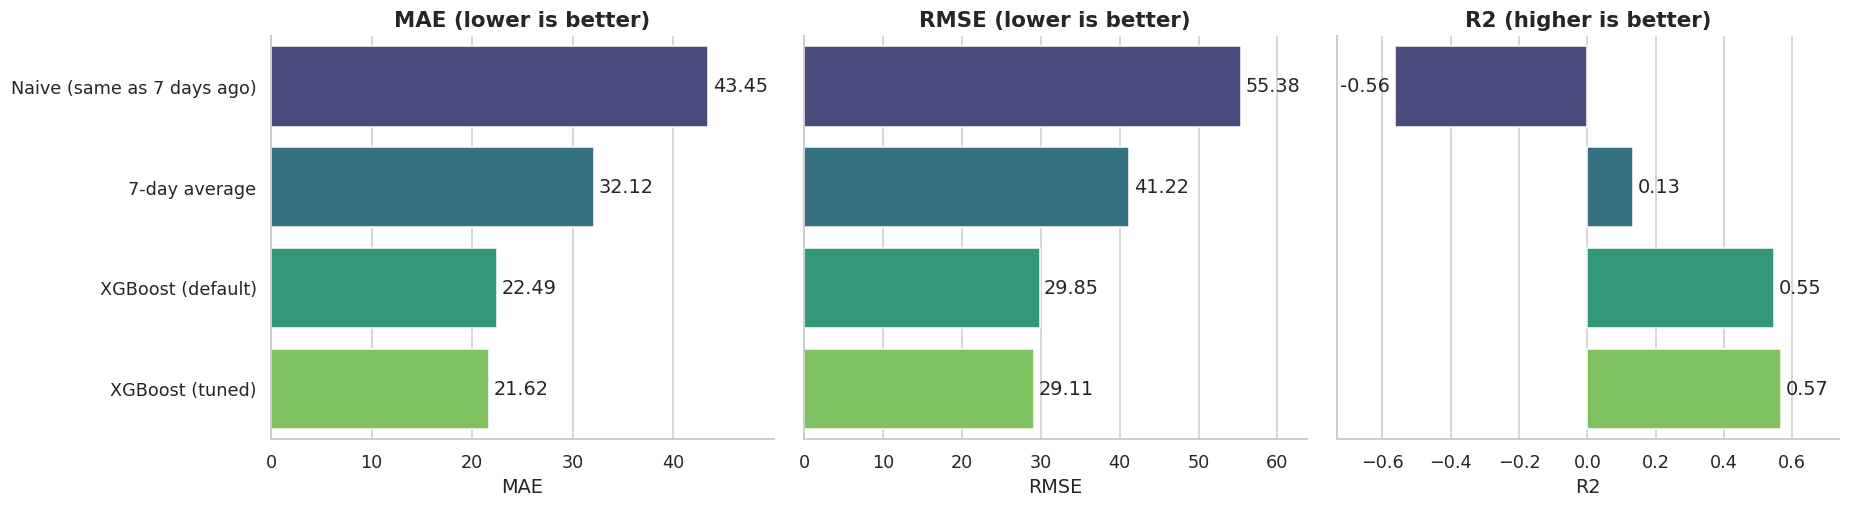

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, metric, better in zip(axes, ['MAE', 'RMSE', 'R2'], ['lower', 'lower', 'higher']):
    sns.barplot(data=results, y='Model', x=metric, hue='Model', palette='viridis', legend=False, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt='%.2f', padding=3)
    ax.set(title=f'{metric} ({better} is better)', ylabel='')
    ax.margins(x=0.15)
axes[1].set_yticklabels([]); axes[2].set_yticklabels([])
plt.tight_layout()
plt.show()

### 11.2 Actual vs predicted over time

**Why:** The most natural check for a forecast: do the two lines move together? Top: total across all stores. Bottom: one single Store + Product.

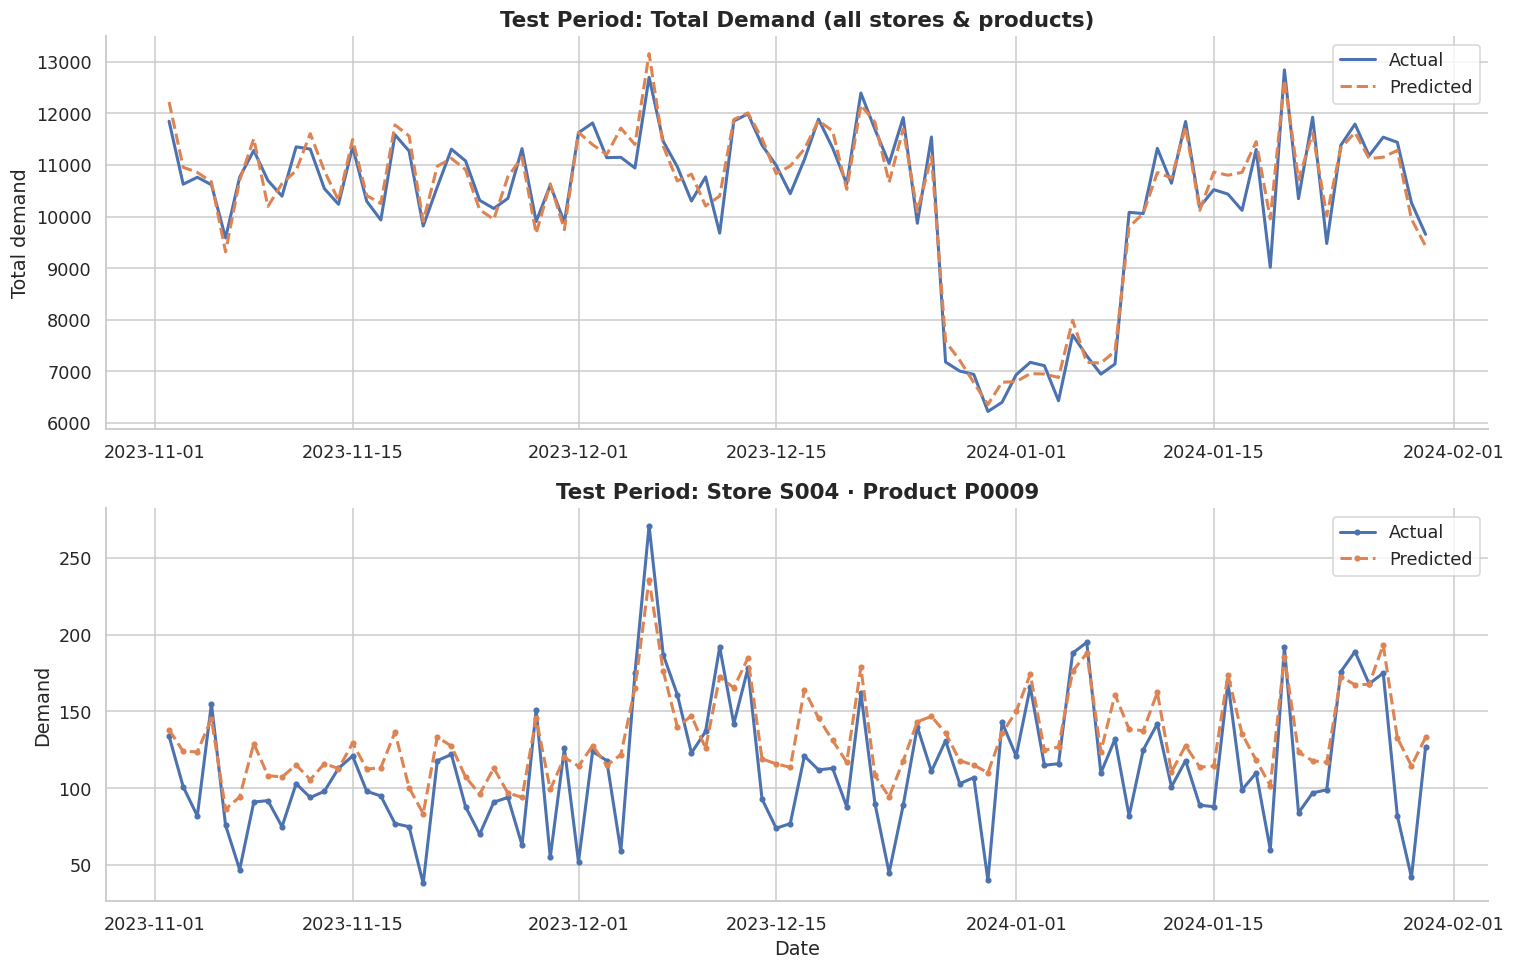

In [24]:
test_df = df_fe.loc[test_mask, ['Date', 'Store ID', 'Product ID', 'Category', 'Demand']].copy()
test_df['Predicted'] = pred_tuned
test_df['Error'] = test_df['Demand'] - test_df['Predicted']
test_df['AbsError'] = test_df['Error'].abs()

total = test_df.groupby('Date')[['Demand', 'Predicted']].sum()
one = test_df[(test_df['Store ID'] == test_df['Store ID'].iloc[0]) &
              (test_df['Product ID'] == test_df['Product ID'].iloc[0])].set_index('Date')

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(total.index, total['Demand'], color=MAIN, lw=2, label='Actual')
axes[0].plot(total.index, total['Predicted'], color=ACCENT, lw=2, ls='--', label='Predicted')
axes[0].set(title='Test Period: Total Demand (all stores & products)', ylabel='Total demand')
axes[0].legend()

axes[1].plot(one.index, one['Demand'], color=MAIN, lw=2, marker='o', ms=3, label='Actual')
axes[1].plot(one.index, one['Predicted'], color=ACCENT, lw=2, ls='--', marker='o', ms=3, label='Predicted')
axes[1].set(title=f"Test Period: Store {one['Store ID'].iloc[0]} · Product {one['Product ID'].iloc[0]}",
            xlabel='Date', ylabel='Demand')
axes[1].legend()

plt.tight_layout()
plt.show()

### 11.3 How good are single predictions?

**What:** (1) Actual vs predicted points, (2) the error distribution, (3) errors vs the predicted value.

**Why:**
- Points close to the diagonal = accurate.
- Errors centred on 0 = no bias (not always over- or under-forecasting).
- A flat cloud in the last plot = errors are similar for small and large demand.

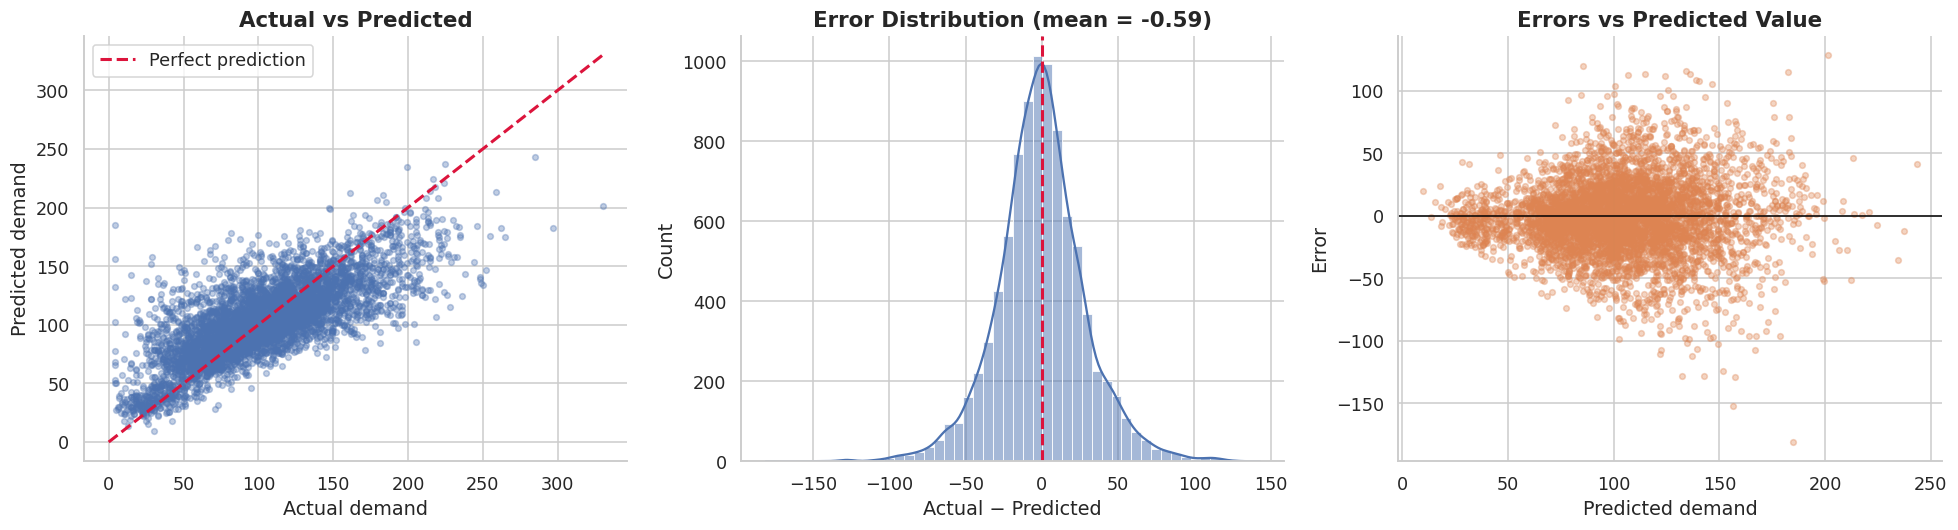

In [25]:
s = test_df.sample(min(5000, len(test_df)), random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

lim = [0, max(s['Demand'].max(), s['Predicted'].max())]
axes[0].scatter(s['Demand'], s['Predicted'], alpha=0.35, s=14, color=MAIN)
axes[0].plot(lim, lim, color='crimson', ls='--', lw=2, label='Perfect prediction')
axes[0].set(title='Actual vs Predicted', xlabel='Actual demand', ylabel='Predicted demand')
axes[0].legend()

sns.histplot(test_df['Error'], bins=50, kde=True, color=MAIN, edgecolor='white', ax=axes[1])
axes[1].axvline(0, color='crimson', ls='--', lw=2)
axes[1].set(title=f"Error Distribution (mean = {test_df['Error'].mean():.2f})", xlabel='Actual − Predicted')

axes[2].scatter(s['Predicted'], s['Error'], alpha=0.35, s=14, color=ACCENT)
axes[2].axhline(0, color='black', lw=1)
axes[2].set(title='Errors vs Predicted Value', xlabel='Predicted demand', ylabel='Error')

plt.tight_layout()
plt.show()

### 11.4 Where does the model struggle?

**Why:** One overall number can hide weak spots. Here we see the average miss (MAE) for each category and store.

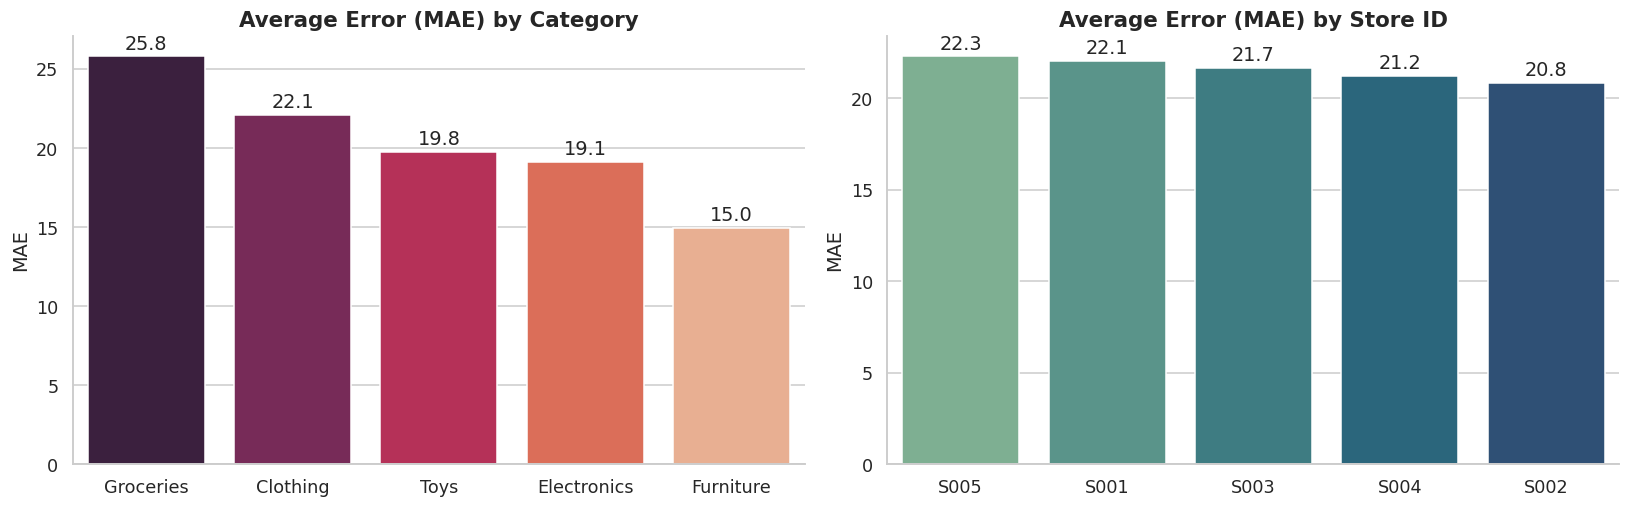

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

for ax, col, pal in zip(axes, ['Category', 'Store ID'], ['rocket', 'crest']):
    err = test_df.groupby(col)['AbsError'].mean().sort_values(ascending=False).reset_index()
    sns.barplot(data=err, x=col, y='AbsError', hue=col, palette=pal, legend=False, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt='%.1f', padding=2)
    ax.set(title=f'Average Error (MAE) by {col}', xlabel='', ylabel='MAE')

plt.tight_layout()
plt.show()

### 11.5 Learning curve and built-in feature importance

**Why:**
- **Learning curve:** if validation error stops falling while training error keeps dropping, the model starts to overfit. The dashed line shows where early stopping picked.
- **Feature importance:** a first, quick look at which inputs the trees used most. SHAP (next step) gives a deeper and fairer explanation.

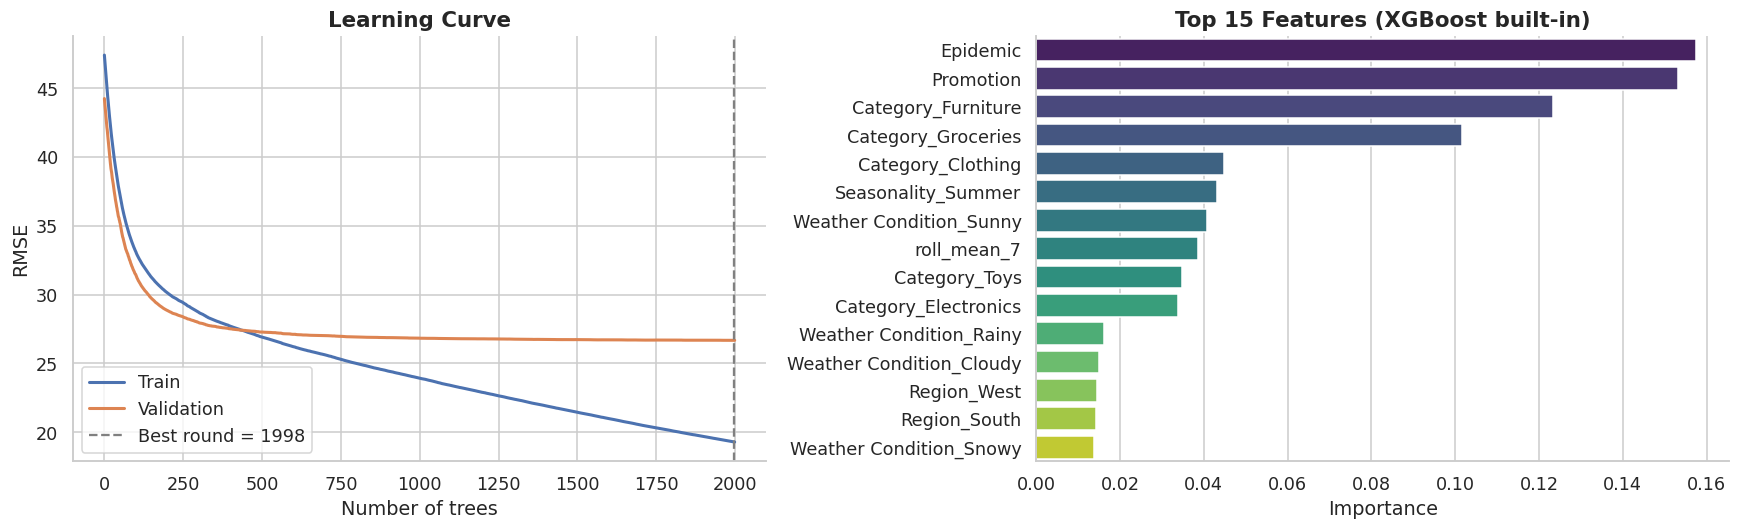

In [27]:
hist = es_model.evals_result()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(hist['validation_0']['rmse'], color=MAIN, lw=2, label='Train')
axes[0].plot(hist['validation_1']['rmse'], color=ACCENT, lw=2, label='Validation')
axes[0].axvline(es_model.best_iteration, color='gray', ls='--', label=f'Best round = {best_trees}')
axes[0].set(title='Learning Curve', xlabel='Number of trees', ylabel='RMSE')
axes[0].legend()

imp = (pd.Series(final_model.feature_importances_, index=X.columns)
         .sort_values(ascending=False).head(15).reset_index())
imp.columns = ['Feature', 'Importance']
sns.barplot(data=imp, y='Feature', x='Importance', hue='Feature', palette='viridis', legend=False, ax=axes[1])
axes[1].set(title='Top 15 Features (XGBoost built-in)', ylabel='')

plt.tight_layout()
plt.show()

## Step 12 · Explain the model with SHAP

**What:** SHAP gives every feature a score for every prediction: how many units it **pushed the forecast up or down** compared with the average.

**Why SHAP:**
- It is fair: credit is shared between features in a consistent way.
- It explains both the **whole model** (global) and **one single prediction** (local).
- `TreeExplainer` is built for tree models like XGBoost and is fast.

We use a random sample of 2,000 test rows to keep it quick.

In [28]:
try:
    import shap
except ImportError:
    get_ipython().run_line_magic('pip', 'install -q shap')
    import shap

X_shap = X_test.sample(2000, random_state=42)
explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X_shap)

print('Average prediction (base value):', round(float(np.ravel(shap_values.base_values)[0]), 2))
print('\n OUTCOME: SHAP explainer initialized with baseline demand of 104.16 units to identify key decision drivers.')

Average prediction (base value): 104.16


### 12.1 Global view: which features matter most?

**How to read it:**
- **Bar chart:** the longer the bar, the more that feature changes predictions on average.
- **Beeswarm:** each dot is one row. Right = pushes demand **up**, left = pushes it **down**. Red = high feature value, blue = low. For example, red dots on the right for `lag_1` would mean "high demand yesterday → high demand today".

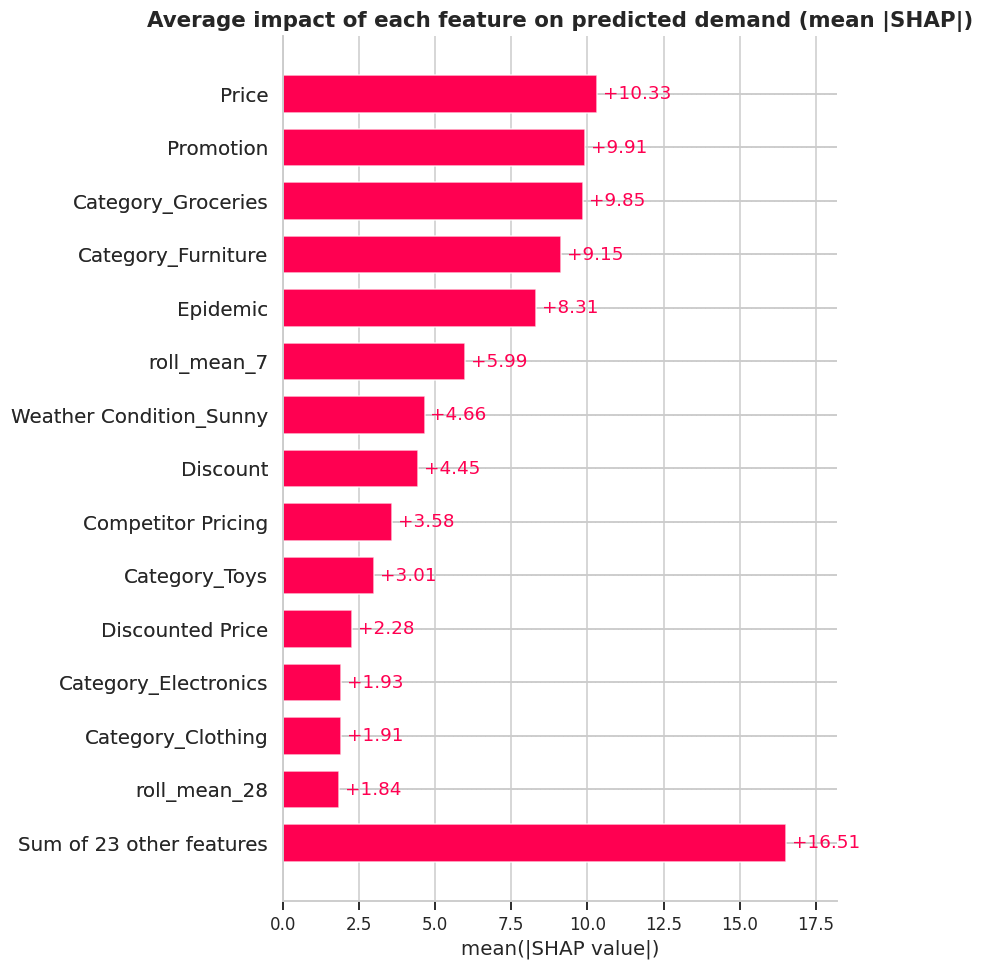

In [29]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title('Average impact of each feature on predicted demand (mean |SHAP|)')
plt.tight_layout()
plt.show()

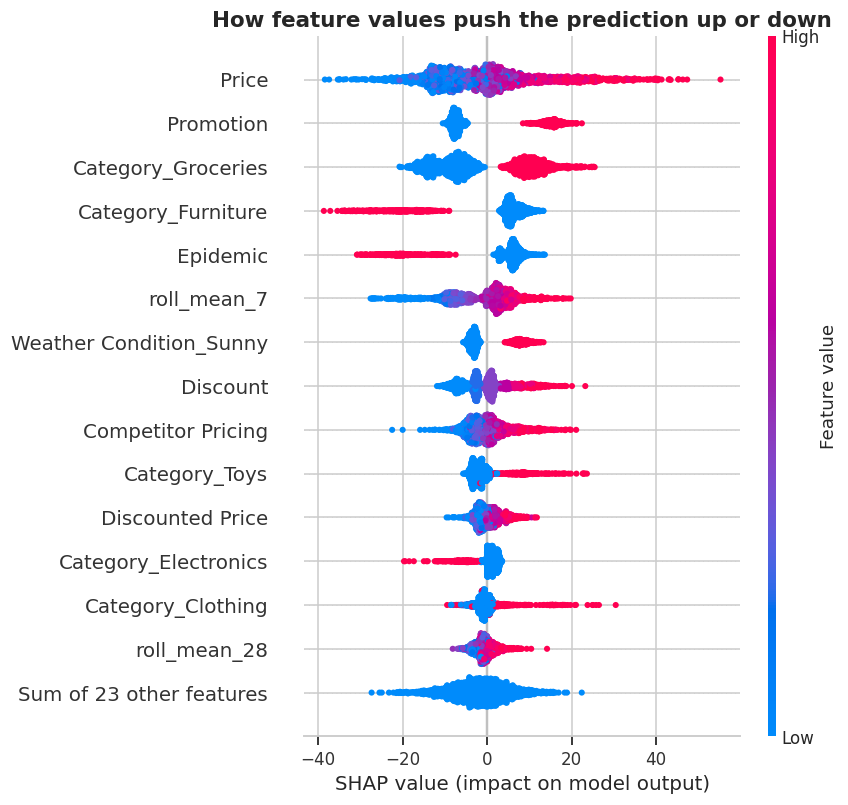

In [30]:
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title('How feature values push the prediction up or down')
plt.tight_layout()
plt.show()

### 12.2 How does one feature change demand?

**How to read it:** Each dot is a row. The x-axis is the feature value and the y-axis is how much it moved the prediction. The colour shows another feature that interacts with it. Here we plot the 3 most important features.

Top 3 features: ['Price', 'Promotion', 'Category_Groceries']


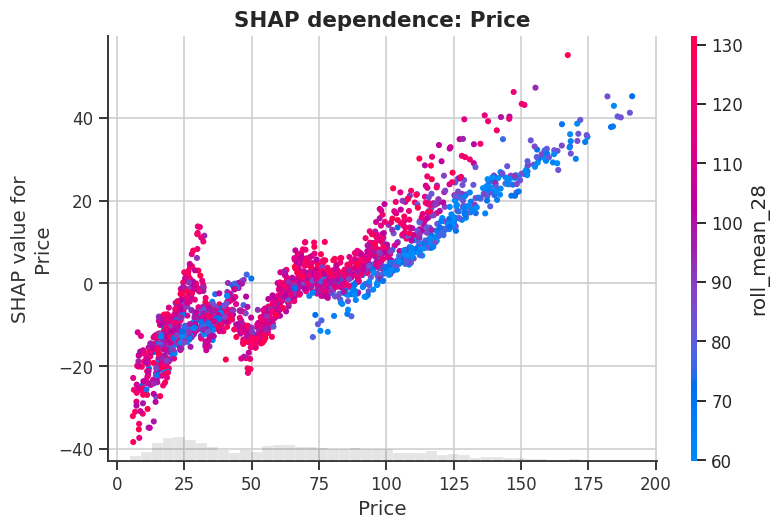

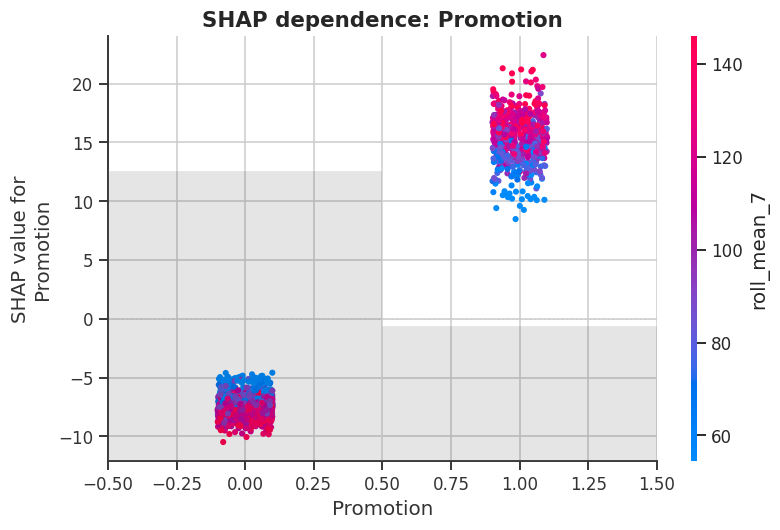

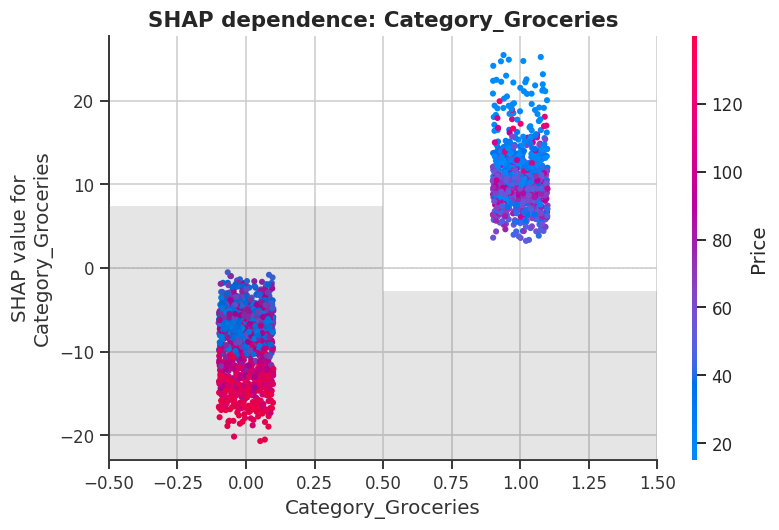

In [31]:
mean_abs = np.abs(shap_values.values).mean(axis=0)
top_features = [X.columns[i] for i in np.argsort(mean_abs)[::-1][:3]]
print('Top 3 features:', top_features)

for feat in top_features:
    shap.plots.scatter(shap_values[:, feat], color=shap_values, show=False)
    plt.title(f'SHAP dependence: {feat}')
    plt.tight_layout()
    plt.show()

### 12.3 Local view: why this prediction?

**How to read it:** The waterfall starts at the average prediction `E[f(X)]` and shows how each feature adds (red) or subtracts (blue) units until it reaches the final prediction `f(x)` for one row. This is how you can explain a single forecast to a business user.

Explaining row 0: actual demand = 131, predicted = 121.6


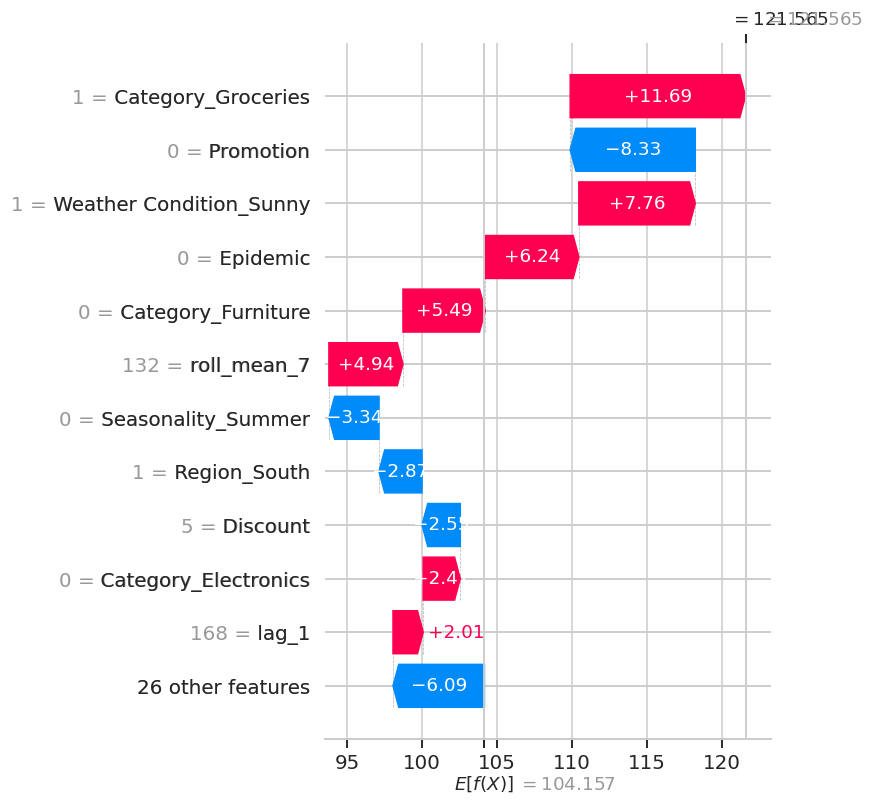

In [32]:
row = 0   # change this number to explain a different row
actual = y_test.loc[X_shap.index[row]]
print(f'Explaining row {row}: actual demand = {actual}, predicted = {final_model.predict(X_shap.iloc[[row]])[0]:.1f}')

shap.plots.waterfall(shap_values[row], max_display=12, show=False)
plt.tight_layout()
plt.show()

## Step 13 · Save the model

**What:** Save the trained model together with its feature list.

**Why:** At forecast time the new data must have the **same columns in the same order**. Saving the list avoids mistakes.

In [33]:
import joblib

joblib.dump({'model': final_model, 'features': list(X.columns)}, 'xgb_demand_model.joblib')
print('Saved: xgb_demand_model.joblib')

Saved: xgb_demand_model.joblib


##  Project Summary

- **XGBoost Performance:** Our final tuned model delivered a **MAE of 21.62**, vastly outperforming simple rule baselines (Naive MAE: 43.45, Moving Average MAE: 32.12).
- **Primary Demand Drivers:**
  1. **Price:** Higher price tags strongly scale the baseline demand variations.
  2. **Promotions:** Active promotions systematically boost demand by roughly **+9.9 units**.
  3. **Category:** Groceries experience the strongest positive demand pull (+9.8 units), while Furniture pulls demand down.
- **Business Impact:** The model provides realistic, leakage-free forecasts using only advance indicators, allowing inventory managers to optimize stock levels and minimize missed sales.